**PÓS-GRADUAÇÃO · DATA SCIENCE & BIG DATA APLICADOS NA INDÚSTRIA**

# Aula 06 · Exercício 02
## Análise de vendas por setor e cliente

| Identificação | Dados |
| :--- | :--- |
| **Aluno** | Carlos Alexandre Duarte Pereira |
| **Curso** | Data Science & Big Data Aplicados na Indústria |
| **Disciplina** | Python para Data Science |
| **Professor** | Me. Daniel Vieira |
| **Data** | 13/11/2026 |

---

**Tema:** agregações com groupby() e gráfico de barras do faturamento por setor.


In [1]:
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:
# 2. CRIAÇÃO DO DATAFRAME
dados = {
    "cliente": ["C1", "C2", "C3", "C4", "C5",
                "C6", "C7", "C8", "C9", "C10"],
    "setor": ["Tecnologia", "Indústria", "Comércio",
              "Tecnologia", "Indústria", "Comércio",
              "Tecnologia", "Indústria", "Comércio", "Tecnologia"],
    "vendas": [1500, 2500, 1200, 3000, 4500,
               2000, 3500, 5000, 2800, 4000]
}
df = pd.DataFrame(dados)
display(df)


,cliente,setor,vendas
0,C1,Tecnologia,1500
1,C2,Indústria,2500
2,C3,Comércio,1200
3,C4,Tecnologia,3000
4,C5,Indústria,4500
5,C6,Comércio,2000
6,C7,Tecnologia,3500
7,C8,Indústria,5000
8,C9,Comércio,2800
9,C10,Tecnologia,4000


In [3]:
# 3. FATURAMENTO TOTAL POR SETOR
faturamento_setor = df.groupby("setor")["vendas"].sum().sort_values(ascending=False)
display(faturamento_setor.to_frame("faturamento_total_rs"))


,faturamento_total_rs
setor,
Indústria,12000
Tecnologia,12000
Comércio,6000


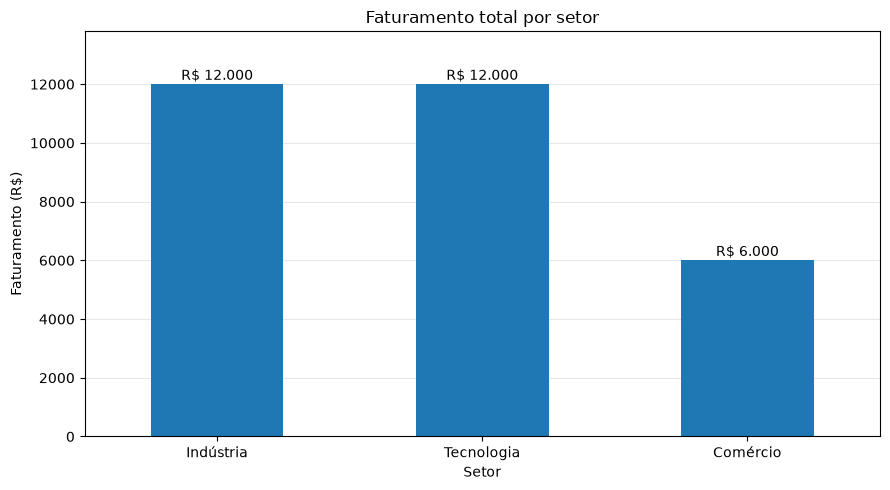

In [4]:
# 4. GRÁFICO DE BARRAS
ax = faturamento_setor.plot(kind="bar", figsize=(9, 5), color="tab:blue", rot=0)
for posicao, valor in enumerate(faturamento_setor):
    ax.text(posicao, valor + 150, f"R$ {valor:,.0f}".replace(",", "."), ha="center")
ax.set_title("Faturamento total por setor")
ax.set_xlabel("Setor")
ax.set_ylabel("Faturamento (R$)")
ax.set_ylim(0, faturamento_setor.max() * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Questões para análise


### a) Qual setor apresentou o maior faturamento?


In [5]:
maior_faturamento = faturamento_setor.max()
# O filtro retorna todos os setores empatados no maior valor.
display(faturamento_setor.loc[faturamento_setor == maior_faturamento].to_frame("faturamento_total_rs"))


,faturamento_total_rs
setor,
Indústria,12000
Tecnologia,12000


**Indústria e Tecnologia** empataram no maior faturamento, com **R$ 12.000,00 cada**.


### b) Qual setor apresentou o menor faturamento?


In [6]:
menor_faturamento = faturamento_setor.min()
display(faturamento_setor.loc[faturamento_setor == menor_faturamento].to_frame("faturamento_total_rs"))


,faturamento_total_rs
setor,
Comércio,6000


O setor de **Comércio** apresentou o menor faturamento: **R$ 6.000,00**.


### c) Qual cliente realizou a compra de maior valor?


In [7]:
maior_venda = df["vendas"].max()
display(df.loc[df["vendas"] == maior_venda, ["cliente", "setor", "vendas"]])


,cliente,setor,vendas
7,C8,Indústria,5000


O cliente **C8**, do setor de Indústria, realizou a compra de maior valor: **R$ 5.000,00**.


### d) Como calcular o faturamento total da empresa utilizando df["vendas"].sum()?


In [8]:
faturamento_total = df["vendas"].sum()
print("Faturamento total: R$", f"{faturamento_total:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))


Faturamento total: R$ 30.000,00


Usamos `df["vendas"].sum()`. O faturamento total da empresa foi de **R$ 30.000,00**.


### e) Como calcular a média das vendas por setor utilizando groupby() e mean()?


In [9]:
media_setor = df.groupby("setor")["vendas"].mean()
display(media_setor.to_frame("media_vendas_rs"))


,media_vendas_rs
setor,
Comércio,2000.0
Indústria,4000.0
Tecnologia,3000.0


Usamos `df.groupby("setor")["vendas"].mean()`. As médias foram: **Comércio: R$ 2.000,00; Indústria: R$ 4.000,00; Tecnologia: R$ 3.000,00**. Cada linha da base representa a venda de um cliente.


## Conclusão

Indústria e Tecnologia tiveram o mesmo faturamento total, mas quantidades diferentes de clientes: três na Indústria e quatro em Tecnologia. Por isso, a média das vendas da Indústria foi maior. O Comércio teve o menor total e a menor média entre os setores analisados.
